In [ ]:
from sklearn . datasets import make_moons
from sklearn . model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow . keras . layers import Dense
from tensorflow . keras import Input

X , y = make_moons ( n_samples =500 , noise =0.2 , random_state =42)
X_train , X_test , y_train , y_test = train_test_split (X , y , test_size =0.3 , random_state =42)

In [ ]:
from tensorflow.keras import initializers

initializer = initializers.GlorotNormal(seed=41)

model = Sequential([
    Input(shape=(2,)),  
    Dense(10, activation="relu", kernel_initializer=initializer),
    Dense(10, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.fit(
    X_train, y_train,
    epochs=40,
    validation_split=0.2,
    verbose=0
)

loss, acc = model.evaluate(X_test, y_test)

E0000 00:00:1781813125.629396 1801989 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8600 - loss: 0.2902


In [14]:
import numpy as np
import matplotlib . pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input , Dense , Flatten
from tensorflow.keras.utils import to_categorical

In [16]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train.shape

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 10s 1us/step


(60000, 28, 28)

In [17]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

y_train_cat = to_categorical(y_train, num_classes=10)
y_test_cat = to_categorical(y_test, num_classes=10)

In [18]:
X_train.shape

(60000, 28, 28)

In [24]:
mod_mnist = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

mod_mnist.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics = ["accuracy"]
)

entrenament = mod_mnist.fit(
    X_train, y_train_cat,
    epochs=20,
    validation_split=0.2
)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9244 - loss: 0.2612 - val_accuracy: 0.9588 - val_loss: 0.1378
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9664 - loss: 0.1098 - val_accuracy: 0.9603 - val_loss: 0.1345
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9761 - loss: 0.0765 - val_accuracy: 0.9688 - val_loss: 0.1086
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9816 - loss: 0.0571 - val_accuracy: 0.9661 - val_loss: 0.1173
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9854 - loss: 0.0450 - val_accuracy: 0.9739 - val_loss: 0.0943
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9894 - loss: 0.0352 - val_accuracy: 0.9678 - val_loss: 0.1185
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9908 - loss: 0.0285 - val_accuracy: 0.9702 - val_loss: 0.1256
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9911 - loss: 0.0270 - 

In [23]:
loss, acc = mod_mnist.evaluate(X_test, y_test_cat)
mod_mnist.summary()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9783 - loss: 0.1131


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 328,160 (1.25 MB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 218,774 (854.59 KB)

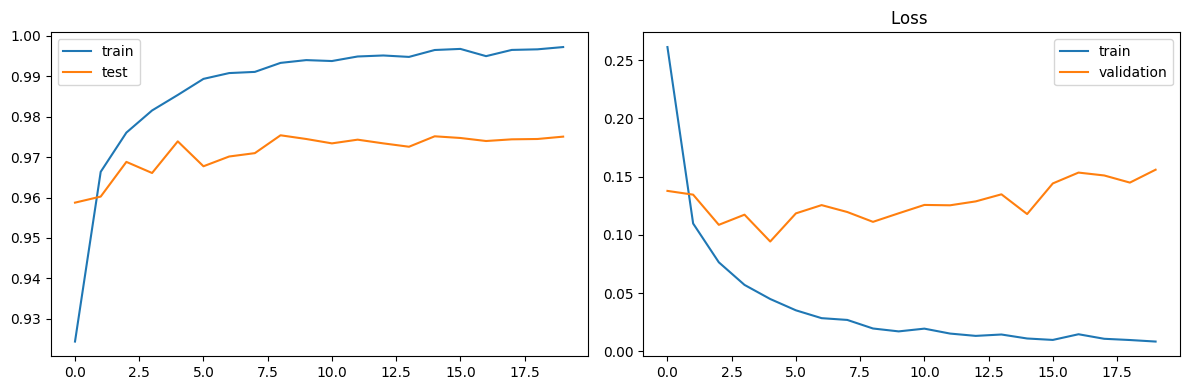

In [33]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(entrenament.history['accuracy'], label="train")
plt.plot(entrenament.history['val_accuracy'], label="test")
plt.legend()

plt.subplot(1,2,2)
plt.plot(entrenament.history['loss'], label ='train')
plt.plot(entrenament.history['val_loss'], label ='validation')
plt.title('Loss ')
plt.legend()

plt.tight_layout()
plt.show()

In [37]:
probs = mod_mnist.predict(X_test)

y_pred = np.argmax(probs, axis=1)

y_pred

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 789us/step


array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (accuracy_score ,confusion_matrix ,classification_report , ConfusionMatrixDisplay)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input , Dense

In [47]:
data = pd.read_csv("spam.csv", encoding="latin-1")

data = data[["v1", "v2"]]
data.columns = ["label", "text"]
data.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [51]:
data['label_num'] = data['label'].map({
    "ham": 0,
    "spam": 1
})

data.head()

,label,text,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [52]:
vectorizer = CountVectorizer(binary=True)
X = vectorizer.fit_transform(data['text']).toarray()
y = data['label_num'].values
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(5572, 8672))

In [53]:
vectorizer.get_feature_names_out()

array(['00', '000', '000pes', ..., 'ûïharry', 'ûò', 'ûówell'],
      shape=(8672,), dtype=object)

In [59]:
X_train, X_test, y_train, y_test, text_train, text_test  = train_test_split(X,y, data['text'].values, test_size=0.2, random_state=123, stratify=y)

In [62]:
X_train.shape

(4457, 8672)

In [64]:
model_spam = Sequential([
    Input(shape=(8672,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(1, activation="sigmoid")
])

model_spam.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

entrenament = model_spam.fit(
    X_train, y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9091 - loss: 0.3032 - val_accuracy: 0.9776 - val_loss: 0.0946
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9935 - loss: 0.0307 - val_accuracy: 0.9798 - val_loss: 0.0741
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9989 - loss: 0.0064 - val_accuracy: 0.9787 - val_loss: 0.0872
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9997 - loss: 0.0021 - val_accuracy: 0.9776 - val_loss: 0.0999
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 0.9787 - val_loss: 0.1085
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 7.4646e-04 - val_accuracy: 0.9787 - val_loss: 0.1156
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 5.2186e-04 - val_accuracy: 0.9787 - val_loss: 0.1206
Epoch 8/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 3.8645e-04 - val_accuracy: 0.9787